## AC Project

In this project, our main goal is to develop a machine learning algorithm that’s able to classify
if a person is at low, medium or high risk of developing diabetes.

## Data Exploration

The full exploratory analysis (class balance, data quality, distributions, correlations and clinical sense check) is in [exploratory_analysis.ipynb](exploratory_analysis.ipynb).

## Imports and Data Initialization

In [12]:
import pandas as pd

data = pd.read_csv('diabetes_risk.csv').drop(columns=['patient_id'])

## Data Partitioning & Data Cleaning

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

SEED = 42
target_col = 'diabetes_risk'

X = data.drop(columns=[target_col])
y = data[target_col]

# 1) 70% train / 30% rest (stratified on the risk class)
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)

# 2) the remaining 30% is split in half: 15% validation / 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED)

print('Data split:')
print('Training:  ', len(X_train))
print('Validation:', len(X_val))
print('Test:      ', len(X_test))

# The class proportions must be the same in the three sets
print()
print(pd.DataFrame({
    'train': y_train.value_counts(normalize=True),
    'validation': y_val.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True),
}).round(3))

Data split:
Training:   10500
Validation: 2250
Test:       2250

               train  validation  test
diabetes_risk                         
Low             0.60        0.60  0.60
Moderate        0.25        0.25  0.25
High            0.15        0.15  0.15


Missing values are filled in after the split, with the most frequent value of the training set (the same values are applied to validation and test, so no information leaks from them).

In [19]:
cols_with_missing = ['smoking_status', 'alcohol_consumption', 'income_bracket']

imputer = SimpleImputer(strategy='most_frequent')
imputer.fit(X_train[cols_with_missing])

for part in (X_train, X_val, X_test):
    part[cols_with_missing] = imputer.transform(part[cols_with_missing])

print('Most frequent values (from the training set):')
print(dict(zip(cols_with_missing, imputer.statistics_)))
print()
print('Missing values left:', X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())

Most frequent values (from the training set):
{'smoking_status': 'Never', 'alcohol_consumption': 'Never', 'income_bracket': 'Middle'}

Missing values left: 0 0 0


## Pre-processing

Everything below is fitted on the **training set only** and then applied to validation and test:
- missing values: most frequent value (as above);
- `family_history_diabetes`: 0/1; ordinal features (`physical_activity_level`, `alcohol_consumption`, `income_bracket`): integers that respect the order;
- nominal features (`gender`, `diet_type`, `smoking_status`, `city`): one-hot encoding;
- numeric and ordinal features: standardised (zero mean, unit variance).

In [20]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler

out_dir = os.path.join('outputs', 'feature_selection')
fig_dir = 'figures'
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

def save_fig(name):
    plt.savefig(os.path.join(out_dir, name), bbox_inches='tight')
    plt.savefig(os.path.join(fig_dir, name), bbox_inches='tight')

order = ['Low', 'Moderate', 'High']

numeric_cols = ['age', 'bmi', 'hours_sleep_per_night', 'stress_level', 'fasting_blood_sugar', 'hba1c_level',
                'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm']
ordinal_cols = ['physical_activity_level', 'alcohol_consumption', 'income_bracket']
ordinal_levels = [['Sedentary', 'Moderate', 'Active'], ['Never', 'Occasional', 'Regular'], ['Low', 'Middle', 'High']]
binary_cols = ['family_history_diabetes']
nominal_cols = ['gender', 'diet_type', 'smoking_status', 'city']

def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), numeric_cols),
        ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('enc', OrdinalEncoder(categories=ordinal_levels)),
                          ('sc', StandardScaler())]), ordinal_cols),
        ('bin', OrdinalEncoder(categories=[['No', 'Yes']]), binary_cols),
        ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), nominal_cols),
    ], verbose_feature_names_out=False).set_output(transform='pandas')

preprocessor = make_preprocessor().fit(X_train)
Xp_train = preprocessor.transform(X_train)
Xp_val = preprocessor.transform(X_val)
Xp_test = preprocessor.transform(X_test)

# columns that are not one-hot indicators (used for the correlation analysis)
continuous_cols = numeric_cols + ordinal_cols + binary_cols

print('Features after encoding:', Xp_train.shape[1])
print('Missing values left:', Xp_train.isna().sum().sum())

Features after encoding: 41
Missing values left: 0


## Feature Selection and Reduction

First the features are ranked with two filter methods (Kruskal-Wallis and ROC-AUC), then redundant features are found with the correlation analysis, and finally PCA and LDA are applied. All of it uses the training set. The impact of each strategy on the performance is measured at the end.

### Kruskal-Wallis

Tests, for each feature, whether its distribution differs between the three risk classes (no normality assumption). With 10 500 patients nearly every p-value is tiny, so the features are ranked by the statistic H (and the effect size epsilon squared = H / (n - 1)), with Holm's correction for the p-values.

In [21]:
from scipy.stats import kruskal

def holm(p):
    # Holm step-down adjusted p-values
    p = np.asarray(p)
    idx = np.argsort(p)
    adj = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[idx]))
    out = np.empty_like(adj)
    out[idx] = adj
    return out

def kruskal_scores(X, y):
    rows = []
    for col in X.columns:
        H, p = kruskal(*[X.loc[y == c, col] for c in order])
        rows.append({'feature': col, 'H': H, 'p': p})
    res = pd.DataFrame(rows).set_index('feature')
    res['epsilon2'] = res['H'] / (len(X) - 1)
    res['p_holm'] = holm(res['p'])
    return res.sort_values('H', ascending=False)

kw = kruskal_scores(Xp_train, y_train)
print(kw.head(15).round(4))
print()
print('Features not significant after Holm correction (5%):', list(kw.index[kw['p_holm'] > 0.05]))
kw.to_csv(os.path.join(out_dir, 'kruskal_wallis.csv'))

                                  H       p  epsilon2  p_holm
feature                                                      
fasting_blood_sugar       5677.5132  0.0000    0.5408  0.0000
hba1c_level               5464.9545  0.0000    0.5205  0.0000
age                        974.1008  0.0000    0.0928  0.0000
bmi                        820.7833  0.0000    0.0782  0.0000
waist_circumference_cm     690.6471  0.0000    0.0658  0.0000
blood_pressure_systolic    529.5536  0.0000    0.0504  0.0000
blood_pressure_diastolic   301.7908  0.0000    0.0287  0.0000
family_history_diabetes    292.7116  0.0000    0.0279  0.0000
physical_activity_level    284.4862  0.0000    0.0271  0.0000
stress_level               101.9874  0.0000    0.0097  0.0000
hours_sleep_per_night       15.1518  0.0005    0.0014  0.0159
city_Kolkata                 9.6270  0.0081    0.0009  0.2436
city_Delhi                   8.0658  0.0177    0.0008  0.5140
diet_type_Vegan              6.3469  0.0419    0.0006  1.0000
city_Sur

### ROC-AUC per feature

Each feature is used on its own as a score for one class versus the rest. The strength is `2 * |AUC - 0.5|` (0 = useless, 1 = perfect), so that a feature that lowers the risk counts as much as one that raises it.

In [22]:
from sklearn.metrics import roc_auc_score

auc = pd.DataFrame({cls: {col: roc_auc_score(y_train == cls, Xp_train[col]) for col in Xp_train.columns}
                    for cls in order})
auc_strength = 2 * (auc - 0.5).abs()
auc_strength['mean'] = auc_strength.mean(axis=1)
auc_strength = auc_strength.sort_values('mean', ascending=False)

print(auc_strength.head(15).round(3))
auc_strength.to_csv(os.path.join(out_dir, 'roc_auc_per_feature.csv'))

                            Low  Moderate   High   mean
fasting_blood_sugar       0.823     0.442  0.899  0.722
hba1c_level               0.806     0.430  0.885  0.707
age                       0.355     0.241  0.314  0.303
bmi                       0.318     0.185  0.326  0.276
waist_circumference_cm    0.291     0.167  0.302  0.253
blood_pressure_systolic   0.257     0.159  0.249  0.222
blood_pressure_diastolic  0.193     0.121  0.186  0.166
physical_activity_level   0.174     0.093  0.190  0.152
family_history_diabetes   0.162     0.123  0.124  0.137
stress_level              0.115     0.085  0.091  0.097
hours_sleep_per_night     0.044     0.032  0.035  0.037
city_Delhi                0.018     0.011  0.017  0.015
income_bracket            0.016     0.010  0.015  0.013
smoking_status_Never      0.007     0.018  0.014  0.013
city_Kolkata              0.012     0.003  0.018  0.011


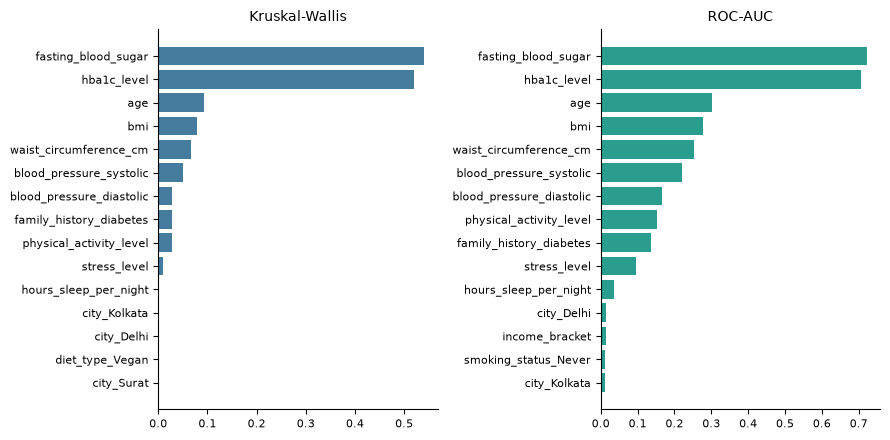

In [26]:
top = 15
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

kw_top = kw.head(top)[::-1]
axes[0].barh(kw_top.index, kw_top['epsilon2'], color='#457b9d')
axes[0].set_title('Kruskal-Wallis', fontsize=10)

auc_top = auc_strength.head(top)[::-1]
axes[1].barh(auc_top.index, auc_top['mean'], color='#2a9d8f')
axes[1].set_title('ROC-AUC', fontsize=10)

for ax in axes:
    ax.tick_params(labelsize=8)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
save_fig('fs_ranking.pdf')
plt.show()

### Correlation analysis

Spearman correlation (robust to outliers and skewness) between the non one-hot features. For each pair with |r| above the threshold, the feature with the lower Kruskal-Wallis statistic is removed.

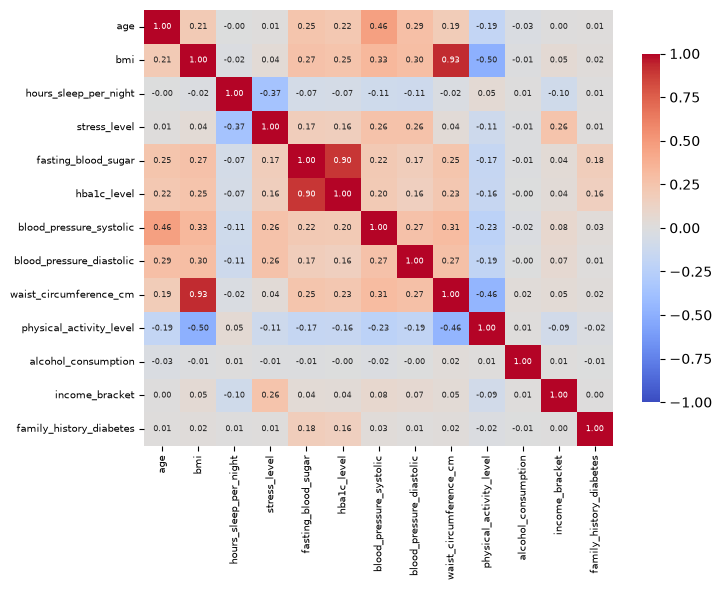

Pairs with |r| > 0.5:
bmi                  waist_circumference_cm    0.93
fasting_blood_sugar  hba1c_level               0.90
dtype: float64

Removed (|r| > 0.9 ): ['waist_circumference_cm']
Features kept: 40


In [27]:
CORR_THRESHOLD = 0.9

def uncorrelated_features(X, scores, threshold=CORR_THRESHOLD):
    corr = X[continuous_cols].corr(method='spearman').abs()
    drop = set()
    for i, a in enumerate(continuous_cols):
        for b in continuous_cols[i + 1:]:
            if corr.loc[a, b] > threshold and a not in drop and b not in drop:
                drop.add(a if scores.loc[a, 'H'] < scores.loc[b, 'H'] else b)
    return [c for c in X.columns if c not in drop], sorted(drop)

corr = Xp_train[continuous_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            annot_kws={'size': 6}, cbar_kws={'shrink': 0.8}, ax=ax)
ax.tick_params(labelsize=7)
plt.tight_layout()
save_fig('fs_correlations.pdf')
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print('Pairs with |r| > 0.5:')
print(pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(2))

kept_cols, dropped_cols = uncorrelated_features(Xp_train, kw)
print()
print('Removed (|r| >', CORR_THRESHOLD, '):', dropped_cols)
print('Features kept:', len(kept_cols))